# Check Pointを正しく読み取れるかどうかの確認

In [64]:
import torch ,torchvision 
from  pathlib import Path
import sys
path = Path("..") / "src/"
sys.path.append(str(path))

from models import get_resnet_frozen
from train import resnet_train 
from evaluate import calculation_test
from dataset import get_dataloaders

resnet_model , optimizer = get_resnet_frozen()

In [65]:
# model_path = Path("..")/"outputs" / "models"/"ResNet18.pth"
model_path = Path("..") / "outputs" / "models" / "resnet_frozen.pth"   # ← 新しいモデル
#テンソル情報を読み込む
state_dict = torch.load(model_path)

#テンソルデータをモデルに落とし込む
resnet_model.load_state_dict(state_dict)

<All keys matched successfully>

In [66]:
for i in resnet_model.parameters():
    print(i)

Parameter containing:
tensor([[[[-1.0419e-02, -6.1356e-03, -1.8098e-03,  ...,  5.6615e-02,
            1.7083e-02, -1.2694e-02],
          [ 1.1083e-02,  9.5276e-03, -1.0993e-01,  ..., -2.7124e-01,
           -1.2907e-01,  3.7424e-03],
          [-6.9434e-03,  5.9089e-02,  2.9548e-01,  ...,  5.1972e-01,
            2.5632e-01,  6.3573e-02],
          ...,
          [-2.7535e-02,  1.6045e-02,  7.2595e-02,  ..., -3.3285e-01,
           -4.2058e-01, -2.5781e-01],
          [ 3.0613e-02,  4.0960e-02,  6.2850e-02,  ...,  4.1384e-01,
            3.9359e-01,  1.6606e-01],
          [-1.3736e-02, -3.6746e-03, -2.4084e-02,  ..., -1.5070e-01,
           -8.2230e-02, -5.7828e-03]],

         [[-1.1397e-02, -2.6619e-02, -3.4641e-02,  ...,  3.2521e-02,
            6.6221e-04, -2.5743e-02],
          [ 4.5687e-02,  3.3603e-02, -1.0453e-01,  ..., -3.1253e-01,
           -1.6051e-01, -1.2826e-03],
          [-8.3730e-04,  9.8420e-02,  4.0210e-01,  ...,  7.0789e-01,
            3.6887e-01,  1.2455e-01]

In [67]:
for i in resnet_model.parameters():
    print(i.requires_grad)
    

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True


In [68]:
train_data , val_data , test_data = get_dataloaders()

In [69]:
resnet_model.eval()
accuracy, precision, recall, F1, false_detect = calculation_test(resnet_model , test_data)

[[380 153  10  81]]
epoch 0: mean_loss = 0.36049524656473064


In [70]:
print( f"acc : {accuracy}" ,
f"precision : {precision}" , 
f"recall : {recall}",
f"F1 : {F1}")

acc : 0.8541666666666666 precision : 0.824295010845987 recall : 0.9743589743589743 F1 : 0.8930669800235016


## 量子化前のモデルサイズとCPU推論時間の測定

In [71]:
# モデルのファイルサイズを取得
model_path.stat().st_size

44788427

In [72]:
import time
import numpy as np
def mesuare_interface_time(model , data):
    time_list = []
    for epoch in range(6):
        start_time = time.time()
        for images , labels in data :
            with torch.no_grad():
                outputs = model(images)
        end_time = time.time()
        total_time = end_time - start_time
        print(f"処理時間 :{total_time}")
        if epoch >= 3:
            time_list.append(total_time)

    time_std =np.std(time_list)
    time_mean = np.mean(time_list)
    print(f"time std : {time_std}",
          f"time mean : { time_mean}")
    return time_list , time_std , time_mean


In [73]:
time_list , time_std , time_mean = mesuare_interface_time(resnet_model , test_data)

処理時間 :15.35197114944458
処理時間 :15.130433082580566
処理時間 :15.190517902374268
処理時間 :15.389955997467041
処理時間 :15.885299921035767
処理時間 :15.230266094207764
time std : 0.27887388270772845 time mean : 15.501840670903524


### 動的量子化

In [74]:
print(torch.backends.quantized.supported_engines)

['qnnpack']


In [75]:
torch.backends.quantized.engine = "qnnpack"

In [76]:
import torch.nn as nn 
quantized_model = torch.quantization.quantize_dynamic(
    resnet_model,
    {nn.Linear},
    dtype=torch.qint8
)

/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/3070773141.py:2: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.quantization.quantize_dynamic(


In [77]:
quantum_model_path = Path("..")/"outputs" / "models" / "quantization" / "quantum_resnet18.pth"
torch.save(quantized_model.state_dict(), quantum_model_path)

In [78]:
quantum_model_path.stat().st_size

44786521

In [79]:
quantized_model.eval()

quantum_acc , quantum_precision , quantum_recall ,  quantum_F1  ,false_detect= calculation_test(quantized_model , test_data)


[[380 153  10  81]]
epoch 0: mean_loss = 0.36438188571721697


##　テストの精度比較

In [80]:
print(f"acc : {quantum_acc}",
    f"precision :{quantum_precision}",
    f"recall : {quantum_recall}",
    f"F1 : {quantum_F1}")

acc : 0.8541666666666666 precision :0.824295010845987 recall : 0.9743589743589743 F1 : 0.8930669800235016


## 量子化によって推論処理時間を比較する

In [81]:
quantum_time_list , quantum_time_std , quantum_time_mean = mesuare_interface_time(quantized_model,test_data)

処理時間 :15.161989212036133
処理時間 :15.191942930221558
処理時間 :15.088958978652954
処理時間 :15.122091054916382
処理時間 :14.998347043991089
処理時間 :15.143435001373291
time std : 0.06396062996317356 time mean : 15.087957700093588


## 動的量子化の結論

・精度面は同じ

・ファイルサイズ
nnLinearのfc部分であり、全体の0.1%ほどのため
ほぼ同じ
多少量子化した方が小さい（微々たるもの）

・推移処理時間
量子化した方が処理時間が増加した。
CNN中心のResNet18モデルには動的量子化は向いていない結果になった。

In [82]:
resnet_model.qconfig = torch.quantization.get_default_qconfig("qnnpack")

In [83]:
prepared_model = torch.quantization.prepare(resnet_model)

/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/49327259.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared_model = torch.quantization.prepare(resnet_model)


In [84]:
data = train_data
model = resnet_model
for images , labels in data :
    with torch.no_grad():
        prepared_model(images)       

In [85]:
print(torch.backends.quantized.engine)

qnnpack


In [86]:
torch.backends.quantized.engine = "qnnpack"

In [87]:
quantized_static_model = torch.quantization.convert(prepared_model)

/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/4030731634.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_static_model = torch.quantization.convert(prepared_model)


In [88]:
quantized_static_model.eval()
QC_acc , QC_precision , QC_recall , QC_F1 , QC_False_detetict = calculation_test(quantized_static_model , test_data)


NotImplementedError: Could not run 'quantized::conv2d.new' with arguments from the 'CPU' backend. This could be because the operator doesn't exist for this backend, or was omitted during the selective/custom build process (if using custom build). If you are a Facebook employee using PyTorch on mobile, please visit https://fburl.com/ptmfixes for possible resolutions. 'quantized::conv2d.new' is only available for these backends: [MPS, Meta, QuantizedCPU, BackendSelect, Python, FuncTorchDynamicLayerBackMode, Functionalize, Conjugate, Negative, ZeroTensor, ADInplaceOrView, AutogradOther, AutogradCPU, AutogradCUDA, AutogradXLA, AutogradMPS, AutogradXPU, AutogradHPU, AutogradLazy, AutogradMTIA, AutogradMAIA, AutogradPrivateUse1, AutogradMeta, Tracer, AutocastCPU, AutocastMTIA, AutocastMAIA, AutocastXPU, AutocastMPS, AutocastCUDA, FuncTorchBatched, BatchedNestedTensor, FuncTorchVmapMode, Batched, VmapMode, FuncTorchGradWrapper, PythonTLSSnapshot, FuncTorchDynamicLayerFrontMode, PreDispatch, P

## 従来のResNet18では、事前の層を変えることはできない

やりたい操作、
forwardの最初にfloatに変換したものを入力
最後に量子化された型を出力するというものを組み合わせたい

In [ ]:
class quantic_resnet_model(nn.Module):
    def __init__(self,model):
        super().__init__()
        self.model = model
        self.quant =torch.quantization.QuantStub()
        self.stub = torch.quantization.DeQuantStub()
    def forward(self,x):
        x = self.quant(x)
        x = self.model(x)
        x = self.stub(x)
        return x
quantization_resnet_model = quantic_resnet_model(resnet_model)
quantization_resnet_model.qconfig = torch.quantization.get_default_qconfig("qnnpack")
prepair_quantization_resnet_model = torch.quantization.prepare(quantization_resnet_model)

data = train_data
for images , labels in data :
    with torch.no_grad():
        prepair_quantization_resnet_model(images)    

quantization_resnet_static_model = torch.quantization.convert(prepair_quantization_resnet_model)

/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/3017244909.py:14: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepair_quantization_resnet_model = torch.quantization.prepare(quantization_resnet_model)
/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/3017244909.py:21: DeprecationWarning: torch.ao.quantization is deprecated and will be rem

In [ ]:
quantization_resnet_static_model.eval()
QC_acc , QC_precision , QC_recall , QC_F1 , QC_False_detetict = calculation_test(quantization_resnet_static_model , test_data)

NotImplementedError: Could not run 'aten::add.out' with arguments from the 'QuantizedCPU' backend. This could be because the operator doesn't exist for this backend, or was omitted during the selective/custom build process (if using custom build). If you are a Facebook employee using PyTorch on mobile, please visit https://fburl.com/ptmfixes for possible resolutions. 'aten::add.out' is only available for these backends: [CPU, MPS, Meta, MkldnnCPU, SparseCPU, SparseMPS, SparseMeta, SparseCsrCPU, SparseCsrMeta, BackendSelect, Python, FuncTorchDynamicLayerBackMode, Functionalize, Conjugate, Negative, ZeroTensor, ADInplaceOrView, AutogradOther, AutogradCPU, AutogradCUDA, AutogradHIP, AutogradXLA, AutogradMPS, AutogradIPU, AutogradXPU, AutogradHPU, AutogradVE, AutogradLazy, AutogradMTIA, AutogradMAIA, AutogradPrivateUse1, AutogradPrivateUse2, AutogradPrivateUse3, AutogradMeta, AutogradNestedTensor, Tracer, AutocastCPU, AutocastMTIA, AutocastMAIA, AutocastXPU, AutocastMPS, AutocastCUDA, Func

In [89]:
dummy=torch.randn(16,3,224,224)

In [90]:
torch.onnx.export()

TypeError: export() missing 1 required positional argument: 'model'

In [91]:
#ResNet が静的量子化の影響を受けていないかを確認する
#Layer 1でactivation post procesがないか
print(resnet_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [92]:
!pip install onnx onnxruntime

zsh:1: /Users/saito/brexa_training/ml-engineer-portfolio-roadmap/01_chest-xray-pneumonia-calssification/.venv/bin/pip: bad interpreter: /Users/saito/ml-engineer-portfolio-roadmap/01_chest-xray-pneumonia-calssification/.venv/bin/python3: no such file or directory
  Using cached onnx-1.23.2-cp312-abi3-macosx_13_0_universal2.whl.metadata (8.7 kB)
ERROR: Could not find a version that satisfies the requirement onnxruntime (from versions: none)
ERROR: No matching distribution found for onnxruntime


In [93]:
model_qc_path = Path("..")/"outputs" / "models" / "quantization" / "ResNet18_qc.onnx"
torch.onnx.export(resnet_model,dummy ,model_qc_path,dynamo=False)

/var/folders/bt/jgp2wlmd2w1bwq829_6z9_mw0000gn/T/ipykernel_56379/2362425552.py:2: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(resnet_model,dummy ,model_qc_path,dynamo=False)


In [94]:
import onnxruntime
session = onnxruntime.InferenceSession(str(model_qc_path))

print(session.get_inputs()[0].name)

input.1


In [95]:
from onnxruntime.quantization import CalibrationDataReader

class MyCalibrationDataReader(CalibrationDataReader):
    def __init__(self, dataloader):
        self.iterator = iter(dataloader)

    def get_next(self):
        try :
            next_data , labels = next(self.iterator)
            data = np.asanyarray(next_data)
            return { "input.1": data}
        except StopIteration:
            return None


In [96]:
new_train_data = MyCalibrationDataReader(train_data)

In [97]:
from onnxruntime.quantization import quantize_static

quantize_model_path = Path("..")/"outputs" / "models" / "quantization" / "quantize_ResNet18.onnx"

quantize_static_resnet18 = quantize_static(model_qc_path ,quantize_model_path,calibration_data_reader=new_train_data)

In [107]:
from torch.utils.data import DataLoader
from dataset import make_dataset, get_transforms, compute_norm_stats, PneumoniaDataset

# eval用のtransform（Augmentationなし）を作る
norm_mean, norm_std = compute_norm_stats("train")
_, eval_transform = get_transforms(norm_mean, norm_std)

# trainから320枚をランダムに選ぶ（再現性のためrandom_stateを固定）
calib_df = make_dataset("train").sample(n=320, random_state=0)
calib_loader = DataLoader(PneumoniaDataset(calib_df, eval_transform),
                          batch_size=16, shuffle=False)

# 別のファイル名で保存して、前の結果と比較できるようにする
quantize_model_path_v2 = Path("..") / "outputs" / "models" / "quantization" / "quantize_ResNet18_evalcalib.onnx"
quantize_static(model_qc_path, quantize_model_path_v2,
                calibration_data_reader=MyCalibrationDataReader(calib_loader))

quant_session_v2 = onnxruntime.InferenceSession(str(quantize_model_path_v2))
acc, prec, rec, f1 = onnx_evaluate(test_data, quant_session_v2)
print("[ONNX int8 / eval-calib]", f"acc: {acc:.4f} precision: {prec:.4f} recall: {rec:.4f} F1: {f1:.4f}")

[ONNX int8 / eval-calib] acc: 0.7436 precision: 0.7106 recall: 0.9949 F1: 0.8291


In [126]:
quantize_model_path_v3 = Path("..") / "outputs" / "models" / "quantization" / "quantize_ResNet18_perchannel.onnx"
quantize_static(model_qc_path, quantize_model_path_v3,
                calibration_data_reader=MyCalibrationDataReader(calib_loader),
                per_channel=True)

quant_session_v3 = onnxruntime.InferenceSession(str(quantize_model_path_v3))
acc, prec, rec, f1 = onnx_evaluate(test_data, quant_session_v3)
print("[ONNX int8 / eval-calib / per-channel]", f"acc: {acc:.4f} precision: {prec:.4f} recall: {rec:.4f} F1: {f1:.4f}")

[ONNX int8 / eval-calib / per-channel] acc: 0.8526 precision: 0.8197 recall: 0.9795 F1: 0.8925


In [143]:
print("[per-channel] size:", quantize_model_path_v3.stat().st_size)
time_list, time_std, time_mean = onnx_time(test_data, quant_session_v3)
print("[per-channel]", f"time_mean: {time_mean:.2f}s std: {time_std:.2f}s")

[per-channel] size: 11294645
5.475276947021484
5.100268125534058
5.026262044906616
5.035704851150513
5.159236192703247
5.03437614440918
[per-channel] time_mean: 5.08s std: 0.06s


In [127]:
quant_session = onnxruntime.InferenceSession(str(quantize_model_path))

print(quant_session.get_outputs()[0].name)

191


In [128]:
outputs = quant_session.run(["191"], {"input.1": images.numpy()})

In [129]:
outputs

[array([[-4.6740227 ,  3.2399476 ],
        [ 1.009164  , -1.5934168 ],
        [-2.3901253 ,  0.6904806 ],
        [-0.21245557, -0.21245557],
        [-1.2747334 , -0.7435945 ],
        [-2.018328  ,  1.1153917 ],
        [ 0.7435945 , -2.018328  ],
        [-2.6556947 ,  0.95605004],
        [-3.0274918 ,  2.3901253 ],
        [-4.142884  ,  1.5403029 ],
        [ 0.31868336, -0.95605004],
        [-4.1959977 ,  2.9212642 ],
        [-4.036656  ,  2.5494668 ],
        [-0.47802502, -0.6373667 ],
        [-0.31868336, -1.5934168 ],
        [-0.42491114, -1.0622778 ]], dtype=float32)]

In [130]:
def onnx_evaluate(data,session):
    TP = FP = TN =FN = 0
    for images , labels in data : 
        pred = session.run(["191"],{"input.1" : images.numpy()})
        pred_label = np.argmax(pred[0],axis=1)
        TP += ((pred_label == 1) & (labels.numpy() == 1)).sum().item()
        FP += ((pred_label == 1) & (labels.numpy() == 0)).sum().item()
        FN += ((pred_label == 0) & (labels.numpy() == 1)).sum().item()
        TN += ((pred_label == 0) & (labels.numpy() == 0)).sum().item()

    accuracy = (TP + TN) / (TP + FP + FN + TN)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    F1 = 2 * precision * recall / (recall + precision)

    return accuracy, precision, recall, F1
        

In [131]:
quant_acc , quant_prexcision ,quant_recall ,quant_F1 = onnx_evaluate(test_data,quant_session)

In [132]:
print(f"acc : {quant_acc}",
      f"precision :{quant_prexcision}",
      f"recall : {quant_recall}",
      f"F1 : {quant_F1}")

acc : 0.7403846153846154 precision :0.708029197080292 recall : 0.9948717948717949 F1 : 0.8272921108742005


In [133]:
##思ったより精度が低いので、ResNetで評価指標に問題がないかの確認
qc_session = onnxruntime.InferenceSession(str(model_qc_path))

In [134]:
qt_acc ,qt_precision ,qt_recall ,qt_F1 = onnx_evaluate(test_data , qc_session)

In [135]:
print(f"acc : {qt_acc}",
    f"precision : {qt_precision}",
    f"recall : {qt_recall}",
    f"F1 : {qt_F1}")

acc : 0.8541666666666666 precision : 0.824295010845987 recall : 0.9743589743589743 F1 : 0.8930669800235016


In [136]:
def onnx_time(data,session):
    time_list = []
    for epoch in range(6):
        start_time = time.time()
        for images , labels in data : 
             session.run(["191"],{"input.1" : images.numpy()})
        end_time = time.time()
        total_time = end_time - start_time
        print(total_time)
        if epoch >=3:
            time_list.append(total_time)
    return time_list , np.std(time_list) , np.mean(time_list)

In [137]:
time_list , time_std , time_mean = onnx_time(test_data, qc_session)

11.597884893417358
11.489408016204834
11.523068904876709
11.61261510848999
11.798064231872559
11.878713846206665


In [138]:
print(f"std :{time_std}",
    f"time_mean :{time_mean}")

std :0.11140729871861621 time_mean :11.763131062189737


In [139]:
time_list , time_std , time_mean = onnx_time(test_data, quant_session)

5.2094268798828125
5.0195231437683105
5.016167879104614
4.989061117172241
4.984112977981567
5.157001972198486


In [140]:
print(f"std :{time_std}",
    f"time_mean :{time_mean}")

std :0.0803597599615728 time_mean :5.043392022450765


In [141]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [142]:
%pip install japanize-matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


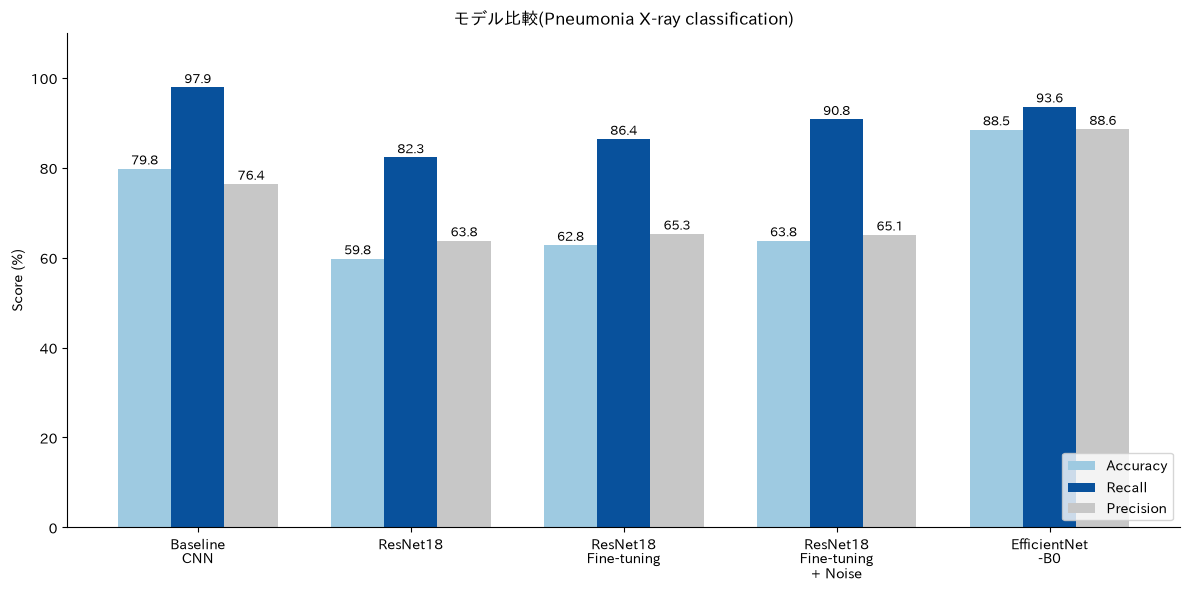

In [124]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import japanize_matplotlib
result = [
    {"model": "Baseline_CNN", "accuracy": 0.798, "precision": 0.764, "recall": 0.979, "F1": 0.858},
    {"model": "ResNet18", "accuracy": 0.598, "precision": 0.638, "recall": 0.823, "F1": 0.719},
    {"model": "ResNet18-Finetuning", "accuracy": 0.628, "precision": 0.653, "recall": 0.864, "F1": 0.744},
    {"model": "ResNet18-Finetuning_Gaussian_noise", "accuracy": 0.638, "precision": 0.651, "recall": 0.908, "F1": 0.758},
    {"model": "EfficientNet-B0", "accuracy": 0.885, "precision": 0.886, "recall": 0.936, "F1": 0.910},
]

# %表記にする
accuracy = [r["accuracy"] * 100 for r in result]
recall = [r["recall"] * 100 for r in result]
precision = [r["precision"] * 100 for r in result]

# 表示用ラベル（元データは変えない）
labels = [
    "Baseline\nCNN",
    "ResNet18",
    "ResNet18\nFine-tuning",
    "ResNet18\nFine-tuning\n+ Noise",
    "EfficientNet\n-B0",
]

x = np.arange(len(result))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - width, accuracy, width, label="Accuracy", color="#9ecae1")
b2 = ax.bar(x, recall, width, label="Recall", color="#08519c")        # 主役: 濃い色
b3 = ax.bar(x + width, precision, width, label="Precision", color="#c7c7c7")

# 棒の上に数値
for bars in (b1, b2, b3):
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 110)
ax.set_title("モデル比較(Pneumonia X-ray classification)")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

# README用に outputs/ ではなく images/ に保存（outputs/ は .gitignore 対象）
Path("../images").mkdir(exist_ok=True)
plt.savefig("../images/model_comparison.png", dpi=200)
plt.show()

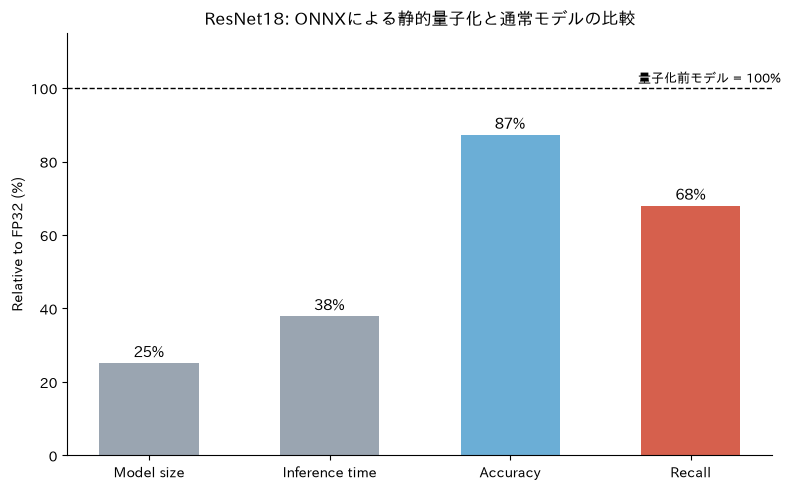

In [125]:
import matplotlib.pyplot as plt
from pathlib import Path

# モデルサイズ（実ファイルから計算）
base_path = Path("../outputs/models/quantization/ResNet18_qc.onnx")
quant_path = Path("../outputs/models/quantization/quantize_ResNet18.onnx")
size_before = base_path.stat().st_size
size_after = quant_path.stat().st_size

# 量子化前 / 後（ONNX fp32 と ONNX 静的量子化、test_data で評価）
time_before, time_after = 29.098, 11.030
acc_before, acc_after = 0.5801, 0.5064
recall_before, recall_after = 0.815, 0.554

labels = ["Model size", "Inference time", "Accuracy", "Recall"]
values = [
    size_after / size_before * 100,
    time_after / time_before * 100,
    acc_after / acc_before * 100,
    recall_after / recall_before * 100,
]
# 小さいほど良い（サイズ・時間）はグレー、精度系は青、Recall だけ赤で強調
colors = ["#9aa5b1", "#9aa5b1", "#6baed6", "#d6604d"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, values, color=colors, width=0.55)
ax.axhline(100, color="black", linestyle="--", linewidth=1)
ax.text(len(labels) - 0.5, 101.5, "量子化前モデル = 100%", ha="right", fontsize=9)

ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=11)
ax.set_ylabel("Relative to FP32 (%)")
ax.set_ylim(0, 115)
ax.set_title("ResNet18: ONNXによる静的量子化と通常モデルの比較")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
Path("../images").mkdir(exist_ok=True)
plt.savefig("../images/quantization_relative.png", dpi=200)
plt.show()

In [ ]:
import onnxruntime as ort
from pathlib import Path

model_dir = Path("..") / "outputs" / "models" / "quantization"

session_fp32 = ort.InferenceSession(str(model_dir / "ResNet18_qc.onnx"))
session_int8 = ort.InferenceSession(str(model_dir / "quantize_ResNet18.onnx"))

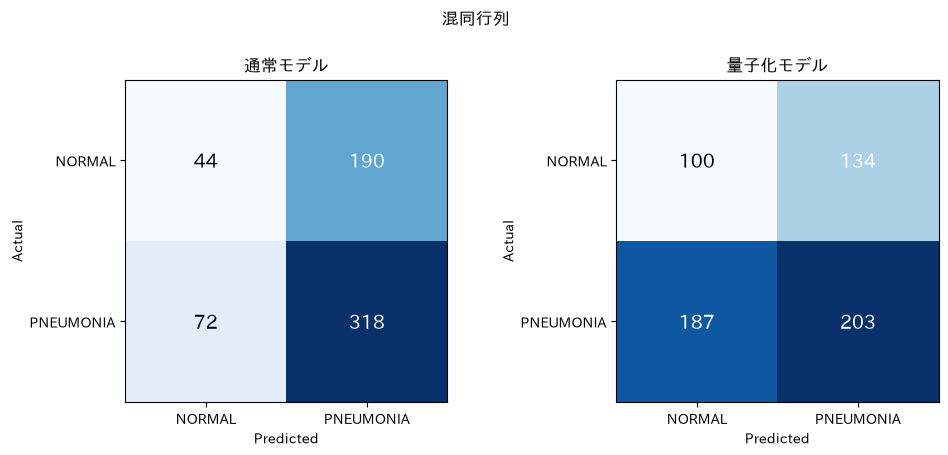

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def onnx_confusion(data, session, input_name="input.1", output_name="191"):
    """[[TN, FP], [FN, TP]] を返す（label 0=NORMAL, 1=PNEUMONIA）"""
    cm = np.zeros((2, 2), dtype=int)
    for images, labels in data:
        pred = session.run([output_name], {input_name: images.numpy()})
        pred_label = np.argmax(pred[0], axis=1)
        for t, p in zip(labels.numpy(), pred_label):
            cm[t, p] += 1
    return cm

# session_fp32 / session_int8 は、それぞれ ONNX fp32 と静的量子化モデルの InferenceSession
cm_before = onnx_confusion(test_data, session_fp32)
cm_after = onnx_confusion(test_data, session_int8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, cm, title in zip(axes, [cm_before, cm_after], ["通常モデル", "量子化モデル"]):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)

plt.suptitle("混同行列", y=1.0)
plt.tight_layout()
Path("../images").mkdir(exist_ok=True)
plt.savefig("../images/quantization_confusion.png", dpi=200)
plt.show()